In [1]:
%matplotlib widget
%run ./LibLogicAnalyserGlitchTools.ipynb

import numpy as np
import matplotlib.pyplot as plt

LA_NAMES = {
    "glitch": [
        "glitch output",
        "glitch src clock",
        "MMCM1 (offset) out",
        "MMCM2 (width) out",
        "glitch go",
        "capture trigger",
        "glitch enable",
        "manual trig (src clk)",
        "trig in MMCM1 clk",
    ],
    "CW 20-pin": ["IO1", "IO2", "IO3", "IO4", "HS1", "HS2",
                  "AUX MCX", "TRIG MCX", "ADC sampling clock"],
    "USERIO 20-pin": ["D0", "D1", "D2", "D3", "D4", "D5", "D6", "D7", "CK"],
}

def make_time_axis(f_la):
    """Return a time_axis(sig, unit) function bound to one sample rate (Hz)."""
    def time_axis(sig, unit='us'):
        scale = {'s': 1, 'ms': 1e3, 'us': 1e6, 'ns': 1e9}[unit]
        return np.arange(len(sig)) / f_la * scale
    return time_axis
    
def plot_interactive(sigs, time_axis, unit, snap=True, channels=None, group="CW 20-pin"):
    """
    channels: None -> all signals
              list of indices, e.g. [0, 1, 4]
              list of names,   e.g. ["IO1", "IO2", "HS1"]
              (order of the list = order of the rows in the plot)
    group:    key in LA_NAMES that provides the channel names
    """
    names = LA_NAMES[group]

    if channels is None:
        channels = list(range(min(len(names), len(sigs))))
    else:
        # convert names to indices, keep indices as they are
        channels = [names.index(c) if isinstance(c, str) else int(c)
                    for c in channels]
    labels = {i: names[i] for i in channels}

    fig, axes = plt.subplots(len(labels), 1,
                             figsize=(12, 1 + 1.0 * len(labels)),
                             sharex=True, squeeze=False)
    axs = axes[:, 0]

    edge_times = []
    for ax, (i, name) in zip(axs, labels.items()):
        sig = np.asarray(sigs[i])
        t = np.asarray(time_axis(sig, unit))
        ax.step(t, sig, where="post")
        ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
        ax.set_yticks([0, 1])
        ax.set_ylim(-0.2, 1.2)
        ax.grid(True, alpha=0.3)
        edge_times.append(t[np.flatnonzero(np.diff(sig) != 0) + 1])
    edges = np.sort(np.concatenate(edge_times))
    axs[-1].set_xlabel(f"time ({unit})")

    help_txt = "Left-click: cursor A/B | Right-click: clear"
    fig.suptitle(help_txt, fontsize=9)
    marks, lines = [], []

    def clear():
        for ln in lines:
            ln.remove()
        lines.clear()
        marks.clear()

    def on_click(event):
        tb = fig.canvas.toolbar
        if tb is not None and getattr(tb, "mode", "") != "":
            return                          # zoom/pan tool is active
        if event.inaxes not in axs:
            return
        if event.button == 3:               # right-click clears
            clear()
            fig.suptitle(help_txt, fontsize=9)
            fig.canvas.draw_idle()
            return
        if event.button != 1:
            return

        x = event.xdata
        if snap and edges.size:
            x = edges[np.argmin(np.abs(edges - x))]
        if len(marks) == 2:
            clear()
        marks.append(x)
        color = "tab:red" if len(marks) == 1 else "tab:green"
        for ax in axs:
            lines.append(ax.axvline(x, color=color, linestyle="--", lw=1))

        if len(marks) == 1:
            msg = f"A = {x:.4g} {unit}"
        else:
            dt = abs(marks[1] - marks[0])
            msg = (f"A = {marks[0]:.4g} {unit}   B = {marks[1]:.4g} {unit}   "
                   f"Δt = {dt:.4g} {unit}")
        fig.suptitle(msg, fontsize=10)
        fig.canvas.draw_idle()

    fig.canvas.mpl_connect("button_press_event", on_click)
    fig.tight_layout()
    plt.show()
    return fig

/tmp/ipykernel_17101/24472307.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(len(labels), 1,


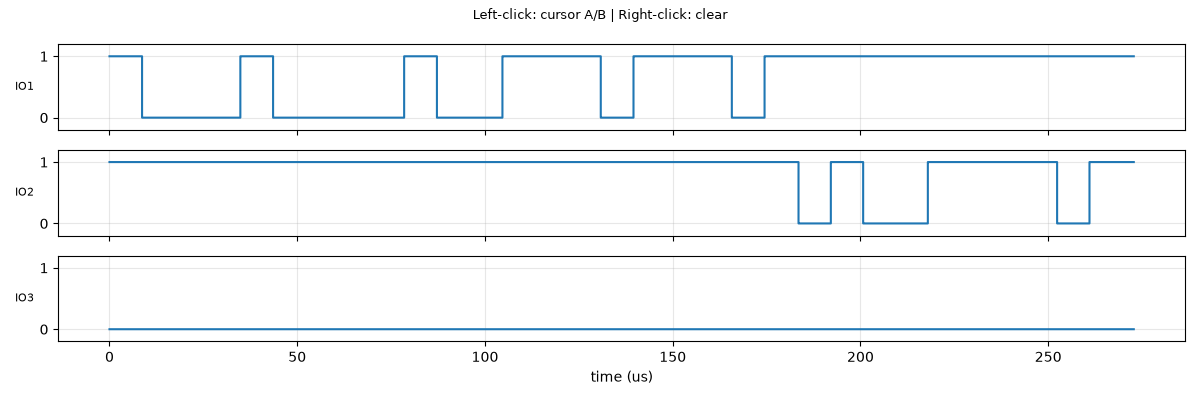

ext_offset=169 (16900 ns)  offset=0 (0 ps)  width=10000 (218 ns)  repeat=10 (pulse 1000 ns)
computed start=17330 ns   measured: delay=14045 ns  pulse=808 ns


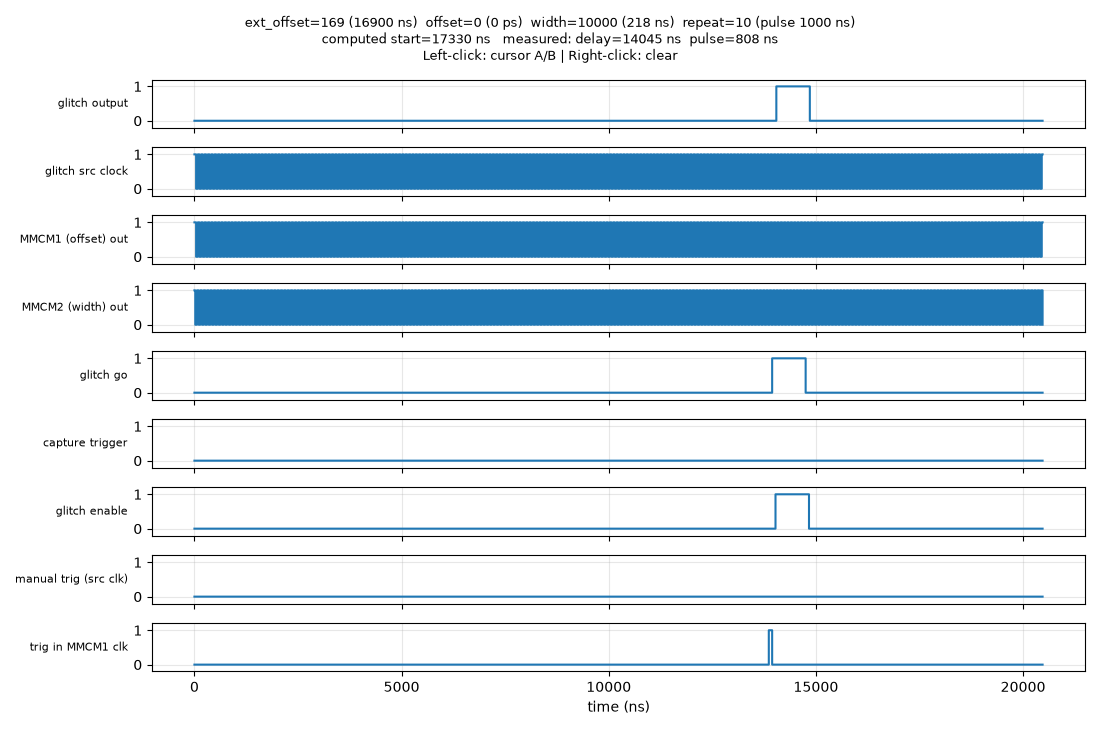

In [15]:
%matplotlib widget
%run ./LibStm32Boot.ipynb
%run ./LibLoadSaveSettings.ipynb
    
    
def init_logic_analyser(scope):
    scope.errors.clear()
    scope.adc.segments = 1
    scope.gain.db = 25
    
    scope.trigger.module = "basic"
    scope.trigger.triggers = "tio1"
    scope.adc.basic_mode = "falling_edge"   # catch the actual start bit
    scope.glitch.trigger_src = "ext_single"   # glitch also fires on that trigger
    scope.adc.presamples = 0
    scope.adc.samples = 10
    scope.adc.lo_gain_errors_disabled = True
    
    # --- Logic analyzer: record trigger + glitch signals ---
    scope.LA.enabled = True
    scope.LA.capture_group = 'CW 20-pin'      # glitch or CW 20-pin
    # other groups: 'CW 20-pin' (shows your trigger pin / IO), 'USB'
    scope.LA.capture_depth = 4000
    scope.LA.trigger_source = 'capture'     
    scope.LA.oversampling_factor = 1       # 1 = highest time resolution
    scope.LA.downsample = 1



FLASH_SIZE = 256      # test
CHUNK = 64                   # SAM3U RX buffer holds only 128-200 bytes
BAUD = 115200
BYTE_GAP = 0.0001              # back-to-back bytes get NACKed by the bootloader
RETRIES = 3
debug=False

out_path = "flash_dump.bin"
size = FLASH_SIZE

try:
    scope.dis()
except:
    pass

scope = cw.scope()
scope.default_setup(verbose=False)
target = cw.target(scope, cw.targets.SimpleSerial)
scope.io.tio1 = "serial_tx"
scope.io.tio2 = "serial_rx"
scope.io.tio3 = "gpio_high"
set_debug_pin(True)

ser = target.ser
ser.setBaud(BAUD)
ser.setParity("even")

init_logic_analyser(scope)


enter_bootloader()
off=0

# Get ID as a sanity check (expect 0462 for the L45x family)
get_product_id()

def trigger_operation():
    data = []
    try:
        data = read_mem(addr, length)
    except Exception as e:
        print(f"exception {e}")
    return data

def pre_arm_action(scope):
    pass

def post_arm_trigger_action(scope):
    trigger_operation()

def post_capture_action(scope):
    pass


def capture_with_la(group, addr, length, glitch=False, trigger='trigger_glitch'):
    scope.errors.clear()

    if glitch:
        scope.glitch.enabled = True
        scope.glitch.clk_src = 'pll'
        scope.glitch.trigger_src = 'ext_single'
        scope.glitch.output = "glitch_only"
        scope.io.glitch_hp = True
        scope.io.glitch_lp = False
    else:
        scope.glitch.enabled = False
        scope.io.glitch_hp = False
        scope.io.glitch_lp = False

    scope.LA.enabled = True
    scope.LA.capture_group = group
    #scope.LA.capture_depth = 2000
    scope.LA.capture_depth = 20000
    scope.LA.downsample = 1   # try 100 to 1000 until you see the whole exchange
    scope.LA.trigger_source = trigger      # direct pin trigger, no ADC involved
    scope.LA.oversampling_factor = 10

    ser.flush()
    time.sleep(0.01)
    scope.LA.arm()                        
    #data = read_chunk_with_retry(addr, length)
    time.sleep(0.003)
    data = trigger_operation()
    
    raw = scope.LA.read_capture_data()
    sigs = {}
    for i in range(9):
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break

    scope.LA.enabled = False
    return sigs, data


addr = FLASH_BASE + off
length = min(CHUNK, size - off)


glitch_graph = True

# --- get the LA's actual sample rate ---
la_rate = scope.LA.sampling_clock_frequency  # Hz; verify this name against print(scope.LA)
sample_period = 1.0 / la_rate                # seconds per LA sample

def time_axis(sig, unit='us'):
    scale = {'s': 1, 'ms': 1e3, 'us': 1e6, 'ns': 1e9}[unit]
    return np.arange(len(sig)) * sample_period * scale



sigs, data = capture_with_la('CW 20-pin', addr, length, glitch=True)
save_scope_settings(scope, "first_capture.json")

f_la = scope.LA.sampling_clock_frequency / scope.LA.downsample
time_axis = make_time_axis(f_la)
unit = 'us'
fig = plot_interactive(sigs, time_axis, unit, snap=True, channels=["IO1", "IO2", "IO3"])

ext_offset = 169
width = 10000
offset = 0
repeat = 10
output="enable_only"
#output="glitch_only"
res = run_glitch(scope, ext_offset=ext_offset, width=width, repeat=repeat, offset=offset, output=output, oversampling=4)
save_scope_settings(scope, "second_capture.json")

print(caption(res))
fig = plot_la_interactive(res["t"] * 1e9, res["sigs"], LA_NAMES["glitch"], unit="ns", title=caption(res))


scope.dis()
scope = None
